In [92]:
import os
import sys
import time
import math
import argparse
from dataclasses import dataclass
from typing import List

import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.utils.data import Dataset
from torch.utils.data.dataloader import DataLoader
#from torch.utils.tensorboard import SummaryWriter

import json

import dis

seed = 3407
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

tmp_x = None
tmp_tok_emb = None
tmp_embs = None

TARGET_GLOBAL = None
LOGITS_GLOBAL = None

#def softmax(x): return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
#def nl(input, target): return -input[range(target.shape[0]), target].log().mean()

def softmax(x): 
    s1 = x
    print( " raw " , s1)
    s2 = x.exp()
    print(" exp " , s2)
    s3 = x.exp().sum()
    print(" sum " , s3)
    s4 = x.exp().sum(-1)
    print(" sum(-1) " , s4)
    s5 = (x.exp().sum(-1)).unsqueeze(-1)
    print(s5)
    s6 = x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
    print(s6)
    return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
    
def nl(input, target): 
    global TARGET_GLOBAL
    print("input", input)
    print("target", target)

    s1 = range(target.shape[0])
    s2 = target.shape[0]
    print(s1)
    print(s2)

    s3 = input[range(target.shape[0]), target]
    print( " s3 " , s3)

    s4 = -input[range(target.shape[0]), target]
    print( " s4 negative : ", s4)

    s5 = -input[range(target.shape[0]), target].log()
    print( " s5 log ", s5)

    p_loss = -input[range(target.shape[0]), target].log().mean()
    print( "loss" , p_loss)

    TARGET_GLOBAL = target
    
    return -input[range(target.shape[0]), target].log().mean()

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.block_size = config.block_size
        self.vocab_size = config.vocab_size
        self.wte = nn.Embedding(config.vocab_size + 1, config.n_embd) # token embeddings table
        # +1 in the line above for a special <BLANK> token that gets inserted if encoding a token
        # before the beginning of the input sequence
        self.mlp = nn.Sequential(
            #nn.Linear(self.block_size * config.n_embd, 27)
            
            nn.Linear(self.block_size * config.n_embd, config.n_embd2),
            nn.Tanh(),
            nn.Linear(config.n_embd2, self.vocab_size)

            
        )

        self.logits_copy = None
        self.targets_copy = None
        self.logits_copy2 = None
        self.targets_copy2 = None

    def get_block_size(self):
        return self.block_size

    def forward(self, idx, targets=None):
        global LOGITS_GLOBAL
        # gather the word embeddings of the previous 3 words
        embs = []
        for k in range(self.block_size):
            tok_emb = self.wte(idx) # token embeddings of shape (b, t, n_embd)

            #print(idx)
            #print(tok_emb)
            
            #global tmp_tok_emb
            #tmp_tok_emb = tok_emb
            
            idx = torch.roll(idx, 1, 1)           
            idx[:, 0] = self.vocab_size # special <BLANK> token          
            embs.append(tok_emb)

            #global tmp_embs
            #tmp_embs = embs
            
        # concat all of the embeddings together and pass through an MLP
        x = torch.cat(embs, -1) # (b, t, n_embd * block_size)

        #global tmp_x
        #tmp_x = x

        print(x.shape)
        logits = self.mlp(x)

        # make copy
        self.logits_copy = logits
        self.targets_copy = targets
        
        
        
        # if we are given some desired targets also calculate the loss
        loss = None
        if targets is not None:
            self.logits_copy2 = logits.view(-1, logits.size(-1))
            self.targets_copy2 = targets.view(-1)
            
            loss_test = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1) # , ignore_index=-1

            LOGITS_GLOBAL = logits.view(-1, logits.size(-1))
                
            print( " SHAPE logits.view(-1, logits.size(-1)) --->", logits.view(-1, logits.size(-1)).shape)
            pred = softmax(logits.view(-1, logits.size(-1)))
            loss=nl(pred, targets.view(-1))

            loss2 = torch.nn.LogSoftmax(dim=1)
            loss_fn = nn.NLLLoss(ignore_index=-1)
            final_loss = loss_fn(loss2(logits.view(-1, logits.size(-1))), targets.view(-1))

            
            print(loss_test , loss, final_loss)

        return logits, loss


##############
class ModelConfig:
    block_size: int = None # length of the input sequences of integers
    vocab_size: int = None # the input integers are in range [0 .. vocab_size -1]
    # parameters below control the sizes of each model slightly differently
    """
    n_layer: int = 4
    n_embd: int = 64
    n_embd2: int = 64
    n_head: int = 4
    """
    
    n_layer: int = 2
    n_embd: int = 2
    n_embd2: int = 2
    n_head: int = 2

config = ModelConfig()

##############
class CharDataset(Dataset):

    def __init__(self, words, chars, max_word_length):
        super().__init__()
        self.words = words
        self.chars = chars
        self.max_word_length = max_word_length
        self.stoi = {ch:i+1 for i,ch in enumerate(chars)}
        self.itos = {i:s for s,i in self.stoi.items()} # inverse mapping

    def __len__(self):
        return len(self.words)

    def contains(self, word):
        return word in self.words

    def get_vocab_size(self):
        return len(self.chars) + 1 # all the possible characters and special 0 token

    def get_output_length(self):
        return self.max_word_length + 1 # <START> token followed by words

    def encode(self, word):
        ix = torch.tensor([self.stoi[w] for w in word], dtype=torch.long)
        return ix

    def decode(self, ix):
        word = ''.join(self.itos[i] for i in ix)
        return word

    def __getitem__(self, idx):
        word = self.words[idx]
        ix = self.encode(word)
        x = torch.zeros(self.max_word_length + 1, dtype=torch.long)
        y = torch.zeros(self.max_word_length + 1, dtype=torch.long)

        x[1:1+len(ix)] = ix
        y[:len(ix)] = ix
        y[len(ix)+1:] = -1 # index -1 will mask the loss at the inactive locations

        return x, y


def create_datasets(input_file):

    # preprocessing of the input text file
    with open(input_file, 'r') as f:
        data = f.read()
    words = data.splitlines()
    words = [w.strip() for w in words] # get rid of any leading or trailing white space
    words = [w for w in words if w] # get rid of any empty strings
    chars = sorted(list(set(''.join(words)))) # all the possible characters
    max_word_length = max(len(w) for w in words)
    print(f"number of examples in the dataset: {len(words)}")
    print(f"max word length: {max_word_length}")
    print(f"number of unique characters in the vocabulary: {len(chars)}")
    print("vocabulary:")
    print(''.join(chars))

    # partition the input data into a training and the test set
    test_set_size = min(1000, int(len(words) * 0.1)) # 10% of the training set, or up to 1000 examples
    rp = torch.randperm(len(words)).tolist()
    train_words = [words[i] for i in rp[:-test_set_size]]
    test_words = [words[i] for i in rp[-test_set_size:]]
    print(f"split up the dataset into {len(train_words)} training examples and {len(test_words)} test examples")

    # wrap in dataset objects
    train_dataset = CharDataset(train_words, chars, max_word_length)
    test_dataset = CharDataset(test_words, chars, max_word_length)

    return train_dataset, test_dataset

class InfiniteDataLoader:


    def __init__(self, dataset, **kwargs):
        train_sampler = torch.utils.data.RandomSampler(dataset, replacement=True, num_samples=int(1e10))
        self.train_loader = DataLoader(dataset, sampler=train_sampler, **kwargs)
        self.data_iter = iter(self.train_loader)

    def next(self):
        try:
            batch = next(self.data_iter)
        except StopIteration: # this will technically only happen after 1e10 samples... (i.e. basically never)
            self.data_iter = iter(self.train_loader)
            batch = next(self.data_iter)
  
        return batch

##############

@torch.no_grad()
def generate(model, idx, max_new_tokens, temperature=1.0, do_sample=False, top_k=None):
    """
    Take a conditioning sequence of indices idx (LongTensor of shape (b,t)) and complete
    the sequence max_new_tokens times, feeding the predictions back into the model each time.
    Most likely you'll want to make sure to be in model.eval() mode of operation for this.
    """
    block_size = model.get_block_size()
    for _ in range(max_new_tokens):
        # if the sequence context is growing too long we must crop it at block_size
        idx_cond = idx if idx.size(1) <= block_size else idx[:, -block_size:]
        # forward the model to get the logits for the index in the sequence
        logits, _ = model(idx_cond)
        # pluck the logits at the final step and scale by desired temperature
        logits = logits[:, -1, :] / temperature
        # optionally crop the logits to only the top k options
        if top_k is not None:
            v, _ = torch.topk(logits, top_k)
            logits[logits < v[:, [-1]]] = -float('Inf')
        # apply softmax to convert logits to (normalized) probabilities
        probs = F.softmax(logits, dim=-1)
        # either sample from the distribution or take the most likely element
        if do_sample:
            idx_next = torch.multinomial(probs, num_samples=1)
        else:
            _, idx_next = torch.topk(probs, k=1, dim=-1)
        # append sampled index to the running sequence and continue
        idx = torch.cat((idx, idx_next), dim=1)

    return idx

def print_samples(num=10):
    """ samples from the model and pretty prints the decoded samples """
    top_k = -1
    X_init = torch.zeros(num, 1, dtype=torch.long).to('cpu')
    top_k = top_k if top_k != -1 else None
    steps = train_dataset.get_output_length() - 1 # -1 because we already start with <START> token (index 0)
    X_samp = generate(model, X_init, steps, top_k=top_k, do_sample=True).to('cpu')
    train_samples, test_samples, new_samples = [], [], []
    for i in range(X_samp.size(0)):
        # get the i'th row of sampled integers, as python list
        row = X_samp[i, 1:].tolist() # note: we need to crop out the first <START> token
        # token 0 is the <STOP> token, so we crop the output sequence at that point
        crop_index = row.index(0) if 0 in row else len(row)
        row = row[:crop_index]
        word_samp = train_dataset.decode(row)
        # separately track samples that we have and have not seen before
        if train_dataset.contains(word_samp):
            train_samples.append(word_samp)
        elif test_dataset.contains(word_samp):
            test_samples.append(word_samp)
        else:
            new_samples.append(word_samp)
    print('-'*80)
    for lst, desc in [(train_samples, 'in train'), (test_samples, 'in test'), (new_samples, 'new')]:
        print(f"{len(lst)} samples that are {desc}:")
        for word in lst:
            print(word)
    print('-'*80)

##############

train_dataset, test_dataset = create_datasets("names.txt")
vocab_size = train_dataset.get_vocab_size()
block_size = train_dataset.get_output_length()

config.vocab_size = vocab_size
config.block_size = block_size
model = MLP(config)

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.01, betas=(0.9, 0.99), eps=1e-8)
#optimizer = torch.optim.SGD(model.parameters(), lr=5e-4, momentum=0)

#batch_loader = InfiniteDataLoader(train_dataset, batch_size=32, pin_memory=False, num_workers=0)
batch_loader = InfiniteDataLoader(train_dataset, batch_size=1, pin_memory=False, num_workers=0)

#batch = batch_loader.next()
#batch = [t for t in batch]
#X, Y = batch

#logits, loss = model(X, Y)

# LOGS
arr0 = []
arr1 = []
arr_grad0 = []

# training loop
best_loss = None
step = 0
while True:

    # get the next batch, ship to device, and unpack it to input and target
    batch = batch_loader.next()
    batch = [t for t in batch]
    X, Y = batch

    # feed into the model
    logits, loss = model(X, Y)

    # collect grads for 0
    #arr0.append(model.wte.weight[0].tolist()[0])
    #arr1.append(model.wte.weight[0].tolist()[1])

    #if model.mlp[0].weight.grad != None:
    #    arr_grad0.append(model.mlp[0].weight.grad[0].mean().item())

    # calculate the gradient, update the weights
    model.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    # logging
    if step % 10 == 0:
        print(f"step {step} | loss {loss.item():.4f} ")

    # sample from the model
    if step > 0 and step % 200 == 0:
        print_samples(num=30)

    step += 1
    
    if step > 2:
        break


number of examples in the dataset: 32033
max word length: 15
number of unique characters in the vocabulary: 26
vocabulary:
abcdefghijklmnopqrstuvwxyz
split up the dataset into 31033 training examples and 1000 test examples
torch.Size([1, 16, 32])
 SHAPE logits.view(-1, logits.size(-1)) ---> torch.Size([16, 27])
 raw  tensor([[ 0.6933, -0.3513, -0.6472, -0.4649, -0.0646, -0.2553, -0.0461, -0.5313,
          0.3001,  0.6867, -0.3004,  0.0563, -0.2646, -0.3171,  0.5003, -0.2247,
         -0.4339,  0.4597, -0.6442, -0.1907, -0.5277,  0.4253, -0.6759,  0.1781,
          0.2923, -0.4079,  0.5775],
        [ 0.6856, -0.3271, -0.6075, -0.3650, -0.1111, -0.2231, -0.0096, -0.5825,
          0.3602,  0.6607, -0.2583,  0.0370, -0.1867, -0.2788,  0.5135, -0.1530,
         -0.4445,  0.3674, -0.6486, -0.2774, -0.4706,  0.4315, -0.7789,  0.0550,
          0.2958, -0.3768,  0.4675],
        [ 0.6425, -0.3711, -0.5373, -0.3201, -0.0756, -0.2228,  0.0517, -0.6555,
          0.4334,  0.6034, -0.2099, -0.0

In [98]:
TARGET_GLOBAL

tensor([26,  8,  1, 22,  9,  1,  8,  0, -1, -1, -1, -1, -1, -1, -1, -1])

In [57]:
TARGET_GLOBAL == -1

tensor([False, False, False, False, False, False, False, False,  True,  True,
         True,  True,  True,  True,  True,  True])

In [99]:
#def softmax(x): return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
#def nl(input, target): return -input[range(target.shape[0]), target].log().mean()

In [195]:
def softmax(x): 
    s1 = x
    #print( " raw " , s1)
    s2 = x.exp()
    #print(" exp " , s2)
    s3 = x.exp().sum()
    #print(" sum " , s3)
    s4 = x.exp().sum(-1)
    #print(" sum(-1) " , s4)
    s5 = (x.exp().sum(-1)).unsqueeze(-1)
    #print(s5)
    s6 = x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
    #print(s6)
    return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)

arr = []

def nl(input, target): 
    print("input", input)
    print("target", target)

    s1 = range(target.shape[0])
    s2 = target.shape[0]
    print(" s1 ", s1)
    print(" s2 ", s2)
    print(" range ", [range(target.shape[0])])
    print(" test1 : ", input[0])
    #print(" test2 : ", input[(0,15),0])

    global arr
    col_idx = 0
    for t in target:
        print(t)
        if (t == -1):
            print(col_idx, "negative")
        elif t != -1:
            print(col_idx, " to arr ")
            arr.append(-input[col_idx].log().mean())
        col_idx += 1

    s3 = input[range(target.shape[0]), target]
    print( " s3 " , s3)

    s4 = -input[range(target.shape[0]), target]
    print( " s4 negative : ", s4)

    s5 = -input[range(target.shape[0]), target].log()
    print( " s5 log ", s5)

    p_loss = -input[range(target.shape[0]), target].log().mean()
    print( "loss" , p_loss)
    
    return -input[range(target.shape[0]), target].log().mean()
    #return arr

In [196]:
#xs = torch.randn(16,27)

In [197]:
pred = softmax(LOGITS_GLOBAL)
loss=nl(pred, TARGET_GLOBAL.view(-1))

input tensor([[0.0734, 0.0258, 0.0189, 0.0227, 0.0341, 0.0282, 0.0344, 0.0217, 0.0486,
         0.0731, 0.0268, 0.0389, 0.0276, 0.0264, 0.0603, 0.0291, 0.0234, 0.0582,
         0.0192, 0.0304, 0.0215, 0.0553, 0.0188, 0.0442, 0.0487, 0.0243, 0.0661],
        [0.0763, 0.0283, 0.0186, 0.0252, 0.0305, 0.0297, 0.0341, 0.0218, 0.0492,
         0.0751, 0.0271, 0.0408, 0.0283, 0.0271, 0.0636, 0.0327, 0.0218, 0.0530,
         0.0196, 0.0282, 0.0239, 0.0529, 0.0170, 0.0398, 0.0484, 0.0261, 0.0609],
        [0.0590, 0.0197, 0.0269, 0.0256, 0.0455, 0.0274, 0.0469, 0.0157, 0.0683,
         0.0558, 0.0336, 0.0281, 0.0399, 0.0306, 0.0516, 0.0259, 0.0322, 0.0538,
         0.0174, 0.0264, 0.0187, 0.0739, 0.0163, 0.0357, 0.0529, 0.0211, 0.0512],
        [0.0829, 0.0342, 0.0171, 0.0303, 0.0235, 0.0325, 0.0319, 0.0224, 0.0480,
         0.0800, 0.0267, 0.0454, 0.0285, 0.0276, 0.0705, 0.0411, 0.0181, 0.0437,
         0.0203, 0.0243, 0.0293, 0.0464, 0.0141, 0.0324, 0.0466, 0.0301, 0.0523],
        [0.0530, 0

In [175]:
loss

tensor(3.0073, grad_fn=<NegBackward0>)

In [176]:
arr

[tensor(3.3918, grad_fn=<NegBackward0>),
 tensor(3.3881, grad_fn=<NegBackward0>),
 tensor(3.3944, grad_fn=<NegBackward0>),
 tensor(3.3963, grad_fn=<NegBackward0>),
 tensor(3.4194, grad_fn=<NegBackward0>),
 tensor(3.3957, grad_fn=<NegBackward0>),
 tensor(3.3836, grad_fn=<NegBackward0>),
 tensor(3.4523, grad_fn=<NegBackward0>)]

In [188]:
__sum = 0
for i in arr[:]:
    __sum += i.item()

In [189]:
__sum / len(arr[:])

3.402707815170288

In [190]:
len(arr)

8

In [191]:
arr[:]

[tensor(3.3918, grad_fn=<NegBackward0>),
 tensor(3.3881, grad_fn=<NegBackward0>),
 tensor(3.3944, grad_fn=<NegBackward0>),
 tensor(3.3963, grad_fn=<NegBackward0>),
 tensor(3.4194, grad_fn=<NegBackward0>),
 tensor(3.3957, grad_fn=<NegBackward0>),
 tensor(3.3836, grad_fn=<NegBackward0>),
 tensor(3.4523, grad_fn=<NegBackward0>)]

In [64]:
logits.view(-1, logits.size(-1)).shape

torch.Size([16, 27])

In [93]:
LOGITS_GLOBAL.shape

torch.Size([16, 27])

In [17]:
# batch size = 32

In [11]:
model.logits_copy.shape, model.logits_copy2.shape

(torch.Size([30, 15, 27]), torch.Size([512, 27]))

In [15]:
model.targets_copy2.shape

torch.Size([512])

In [18]:
# batch size = 1

In [19]:
model.logits_copy.shape, model.logits_copy2.shape

(torch.Size([30, 15, 27]), torch.Size([16, 27]))

In [20]:
model.targets_copy2.shape

torch.Size([16])

In [22]:
model

MLP(
  (wte): Embedding(28, 2)
  (mlp): Sequential(
    (0): Linear(in_features=32, out_features=2, bias=True)
    (1): Tanh()
    (2): Linear(in_features=2, out_features=27, bias=True)
  )
)

In [24]:
model.logits_copy[0].shape

torch.Size([15, 27])

In [10]:
model.mlp[0]

Linear(in_features=32, out_features=2, bias=True)

In [2]:
from torchviz import make_dot

def render_graph(loss, params, filename="graph", format="png"):
    """
    Renders the autograd graph using torchviz.

    Args:
        loss (torch.Tensor): Final scalar tensor (e.g., loss)
        params (dict): Named parameters to show in graph
        filename (str): Output file name (without extension)
        format (str): File format (png, pdf, etc.)
    """
    dot = make_dot(loss, params=params)
    dot.format = format
    dot.render(filename, cleanup=True)
    return dot

In [23]:
model.mlp[1]

Tanh()

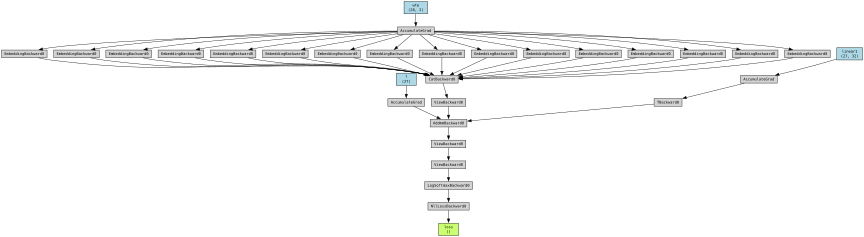

In [31]:
params = {
    "wte": model.wte.weight,
    "linear1" : model.mlp[0].weight,
    "?" : model.mlp[0].bias,
    "loss": loss
}

render_graph(loss, params, filename="logistic_graph")

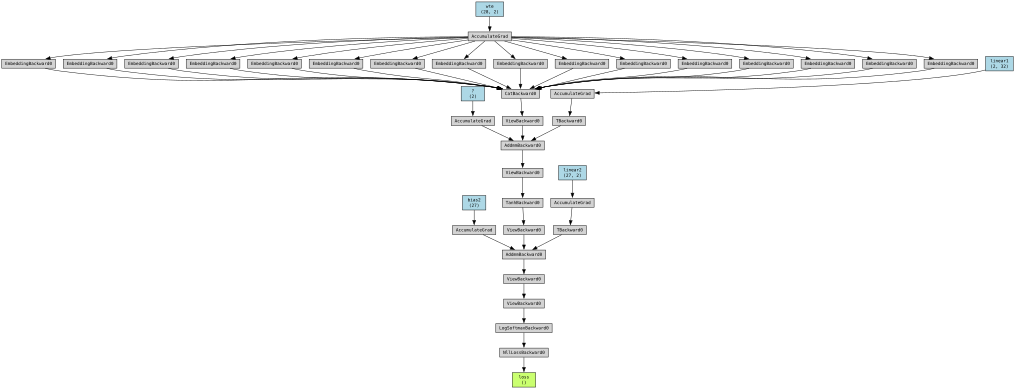

In [33]:
params = {
    "wte": model.wte.weight,
    "linear1" : model.mlp[0].weight,
    "?" : model.mlp[0].bias,
    "linear2" : model.mlp[2].weight,
    "bias2" : model.mlp[2].bias,
    "loss": loss
}

render_graph(loss, params, filename="logistic_graph")

In [34]:
model

MLP(
  (wte): Embedding(28, 2)
  (mlp): Sequential(
    (0): Linear(in_features=32, out_features=2, bias=True)
    (1): Tanh()
    (2): Linear(in_features=2, out_features=27, bias=True)
  )
)

In [36]:
logits.shape

torch.Size([32, 16, 27])

In [40]:
# transformer

In [41]:
model

MLP(
  (transformer): ModuleDict(
    (wte): Embedding(27, 2)
    (wpe): Embedding(16, 2)
    (h): ModuleList(
      (0-1): 2 x Block(
        (ln_1): LayerNorm((2,), eps=1e-05, elementwise_affine=True)
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=2, out_features=6, bias=True)
          (c_proj): Linear(in_features=2, out_features=2, bias=True)
        )
        (ln_2): LayerNorm((2,), eps=1e-05, elementwise_affine=True)
        (mlp): ModuleDict(
          (c_fc): Linear(in_features=2, out_features=8, bias=True)
          (c_proj): Linear(in_features=8, out_features=2, bias=True)
          (act): NewGELU()
        )
      )
    )
    (ln_f): LayerNorm((2,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=2, out_features=27, bias=False)
)

In [44]:
model.transformer.wte.weight

Parameter containing:
tensor([[-1.7216,  0.6717],
        [-0.4541, -0.4646],
        [ 0.9282,  0.1455],
        [ 0.6500,  0.0756],
        [-1.2856,  0.9736],
        [ 0.1882,  0.6584],
        [-0.4497, -0.9423],
        [ 2.1943, -0.3706],
        [ 0.9969,  0.7518],
        [ 0.3593,  0.7828],
        [ 0.9377, -2.2372],
        [ 0.7460, -1.3128],
        [ 0.7812, -0.0548],
        [-0.2954, -0.7012],
        [ 0.1492,  0.1802],
        [-1.7822, -0.8611],
        [ 0.5000,  0.0463],
        [-2.2055, -0.8418],
        [-0.9021,  0.4258],
        [-1.0709,  1.9715],
        [-0.0563,  0.8080],
        [ 1.3563, -0.9931],
        [ 1.0522, -0.9733],
        [ 0.8209,  2.6759],
        [-0.3255, -0.7019],
        [ 1.4925,  0.1041],
        [-0.8089, -1.0201]], requires_grad=True)

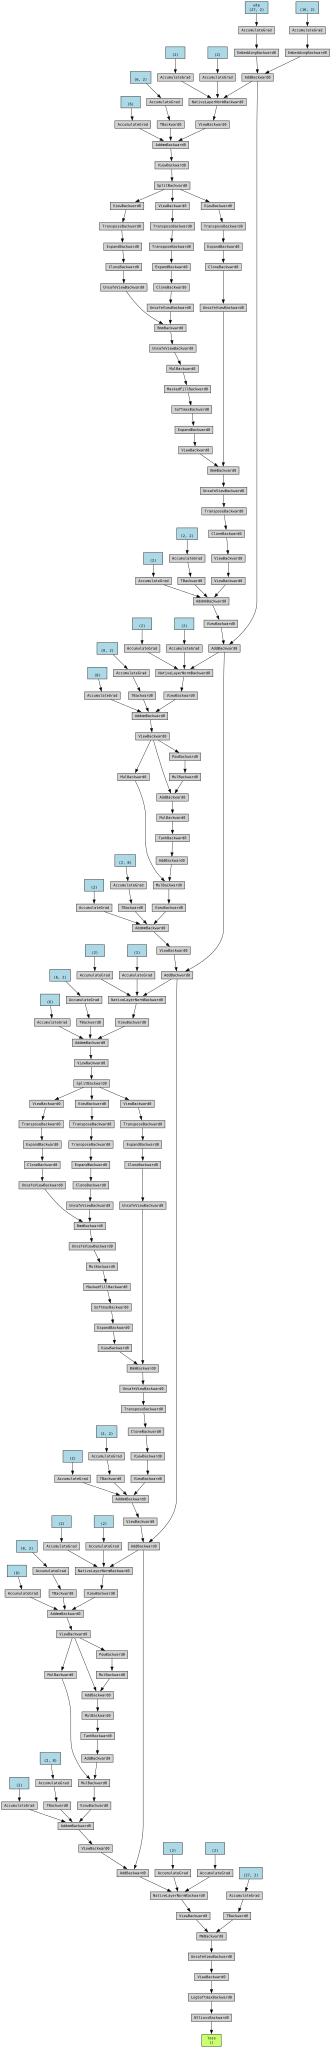

In [45]:
params = {
    "wte" : model.transformer.wte.weight,
    "loss": loss
}

render_graph(loss, params, filename="logistic_graph")

In [3]:


"""
# transformer 
# -----------------------------------------------------------------------------
# Transformer Language Model (*exactly* as used in GPT-2)

class NewGELU(nn.Module):
    """
    Implementation of the GELU activation function currently in Google BERT repo (identical to OpenAI GPT).
    Reference: Gaussian Error Linear Units (GELU) paper: https://arxiv.org/abs/1606.08415
    """
    def forward(self, x):
        return 0.5 * x * (1.0 + torch.tanh(math.sqrt(2.0 / math.pi) * (x + 0.044715 * torch.pow(x, 3.0))))

class CausalSelfAttention(nn.Module):
    """
    A vanilla multi-head masked self-attention layer with a projection at the end.
    It is possible to use torch.nn.MultiheadAttention here but I am including an
    explicit implementation here to show that there is nothing too scary here.
    """

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        # causal mask to ensure that attention is only applied to the left in the input sequence
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size))
        self.n_head = config.n_head
        self.n_embd = config.n_embd

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)

        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        q, k ,v  = self.c_attn(x).split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)

        # causal self-attention; Self-attend: (B, nh, T, hs) x (B, nh, hs, T) -> (B, nh, T, T)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side

        # output projection
        y = self.c_proj(y)
        return y

class Block(nn.Module):
    """ an unassuming Transformer block """

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = nn.ModuleDict(dict(
            c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd),
            c_proj  = nn.Linear(4 * config.n_embd, config.n_embd),
            act     = NewGELU(),
        ))
        m = self.mlp
        self.mlpf = lambda x: m.c_proj(m.act(m.c_fc(x))) # MLP forward

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlpf(self.ln_2(x))
        return x

class MLP(nn.Module):
    """ Transformer Language Model, exactly as seen in GPT-2 """

    def __init__(self, config):
        super().__init__()
        self.block_size = config.block_size

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # report number of parameters (note we don't count the decoder parameters in lm_head)
        n_params = sum(p.numel() for p in self.transformer.parameters())
        print("number of parameters: %.2fM" % (n_params/1e6,))

    def get_block_size(self):
        return self.block_size

    def forward(self, idx, targets=None):
        device = idx.device
        b, t = idx.size()
        assert t <= self.block_size, f"Cannot forward sequence of length {t}, block size is only {self.block_size}"
        pos = torch.arange(0, t, dtype=torch.long, device=device).unsqueeze(0) # shape (1, t)

        # forward the GPT model itself
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (b, t, n_embd)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (1, t, n_embd)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)

        # if we are given some desired targets also calculate the loss
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1)

        return logits, loss
"""


IndentationError: unexpected indent (2337298859.py, line 8)